# 04 — Measurements

Homodyne, heterodyne, and general-dyne measurements: conditional states,
sampling statistics, and detector imperfections (efficiency, electronic
noise).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvcircuit as cv

np.set_printoptions(precision=4, suppress=True)
rng_seed = 0

## Homodyne: conditional squeezing of an EPR pair

Every measurement returns `(outcome, conditional_state)`. The measured
mode is reset to vacuum and kept in place -- mode indices never shift.
Measuring the x-quadrature of one half of a two-mode squeezed vacuum
(TMSV) conditionally squeezes the *other* half -- the mechanism behind CV
teleportation and CV-QKD.

In [2]:
epr = cv.two_mode_squeezed(1.2)
outcome, conditional = epr.homodyne(mode=0, angle=0.0, seed=rng_seed)
print("outcome:", outcome)
print("mode 1 conditional Var(x):", conditional.reduced([1]).quad_variance(0, 0.0), "(vacuum = 1)")
print("mode 1 conditional Var(p):", conditional.reduced([1]).quad_variance(0, np.pi / 2), "(unconditioned)")

outcome: 0.29638608702849534
mode 1 conditional Var(x): 0.1799549230816373 (vacuum = 1)
mode 1 conditional Var(p): 5.556947166965506 (unconditioned)


## Sampling statistics: many shots

Running the same measurement many times traces out the analytic Gaussian
outcome distribution.

sample var: 0.36214574418403594  analytic var: 0.36787944117144217


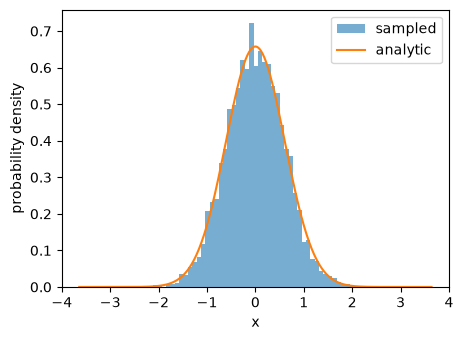

In [3]:
squeezed_state = cv.squeezed(0.5)
outcomes = np.array([squeezed_state.homodyne(mode=0, angle=0.0, seed=i)[0] for i in range(4000)])

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.hist(outcomes, bins=60, density=True, alpha=0.6, label="sampled")
xvec, pdf = squeezed_state.marginal(0, angle=0.0)
ax.plot(xvec, pdf, label="analytic")
ax.set_xlabel("x")
ax.set_ylabel("probability density")
ax.legend()
print("sample var:", outcomes.var(), " analytic var:", squeezed_state.quad_variance(0, 0.0))

## Heterodyne

Simultaneous (noisy) measurement of both quadratures; the outcome is a
complex amplitude. It's exactly general-dyne with a vacuum-noise POVM,
`cov_povm = (hbar/2) I`.

sample mean: (1.0219144319528113-0.5199295936555668j)  true alpha: (1-0.5j)


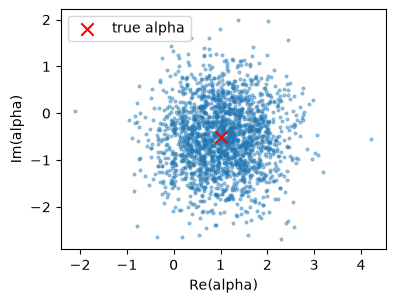

In [4]:
coh = cv.coherent(1.0 - 0.5j)
alphas = np.array([coh.heterodyne(mode=0, seed=i)[0] for i in range(2000)])

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(alphas.real, alphas.imag, s=4, alpha=0.4)
ax.scatter([1.0], [-0.5], color="red", marker="x", s=80, label="true alpha")
ax.set_xlabel("Re(alpha)")
ax.set_ylabel("Im(alpha)")
ax.set_aspect("equal")
ax.legend()
print("sample mean:", alphas.mean(), " true alpha:", 1.0 - 0.5j)

## General-dyne: the common primitive

`generaldyne(modes, cov_povm)` is the single primitive behind both of the
above. A strongly squeezed POVM covariance approaches homodyne in one
quadrature (though `homodyne()` computes that limit exactly, avoiding a
numerically singular matrix inverse).

In [5]:
from cvcircuit import ops

povm_narrow = ops.squeezing(6.0, phi=0.0) @ (epr.hbar / 2 * np.eye(2)) @ ops.squeezing(6.0, phi=0.0).T
_, cond_gd = epr.generaldyne([0], povm_narrow, seed=rng_seed)
_, cond_ho = epr.homodyne(mode=0, angle=0.0, seed=rng_seed)
print("general-dyne (narrow POVM) mode-1 cov:\n", cond_gd.reduced([1]).cov)
print("exact homodyne mode-1 cov:\n", cond_ho.reduced([1]).cov)

general-dyne (narrow POVM) mode-1 cov:
 [[0.18   0.    ]
 [0.     5.5568]]
exact homodyne mode-1 cov:
 [[0.18   0.    ]
 [0.     5.5569]]


## Detector imperfections

`homodyne(..., efficiency=, electronic_noise=)` prepends a loss channel
and additive noise before the projection, modelling a realistic detector.

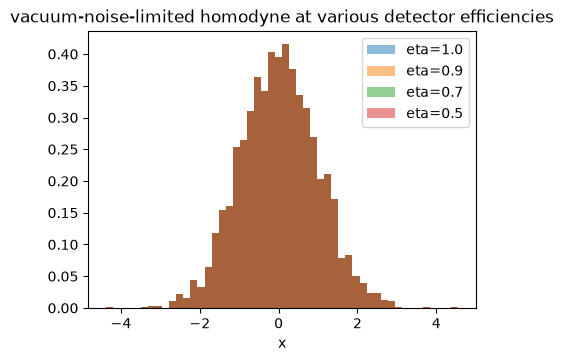

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.6))
for efficiency in [1.0, 0.9, 0.7, 0.5]:
    outcomes = [cv.vacuum(1).homodyne(mode=0, efficiency=efficiency, seed=i)[0] for i in range(3000)]
    ax.hist(outcomes, bins=50, density=True, alpha=0.5, label=f"eta={efficiency}")
ax.set_xlabel("x")
ax.set_title("vacuum-noise-limited homodyne at various detector efficiencies")
ax.legend()

Lower efficiency mixes in more vacuum noise (the detector "sees" less of
the actual signal and more of its own inefficiency-induced noise),
broadening the outcome distribution even for vacuum input.